# Assignment 3 — Code Submission (Jupyter Notebook Template)

**Submit:** this `.ipynb` file inside the required ZIP package, together with the required wav_examples/ folder.

**Group members (Name | ID):**  
- `<NAME 1> | <ID 1>`  
- `<NAME 2> | <ID 2>`  
- `<NAME 3> | <ID 3>`  
- `<NAME 4> | <ID 4>`

**Date:** `<DD Month YYYY>`

---

## What the marker should be able to do (end-to-end)
From a fresh environment, the marker should be able to:

1. **Install dependencies** (from your provided dependencies file)  
2. **Run training** for each experiment (or run your provided trained checkpoints, if allowed by the task sheet)  
3. **Run inference**: input plain text → output a playable `.wav` file  
4. **See evidence**: objective metric(s) + qualitative samples (≥10 text prompts with corresponding `.wav` outputs)

---

## Expected artefacts / recommended structure
You can adapt this, but keep it **clear and reproducible**.

- `dependencies.*` (choose one): `requirements.txt` / `environment.yml` / `pyproject.toml`  
- `scripts/`
  - `train.py` (or `train_expA.py`, `train_expB.py`, etc.)
  - `synth.py` (single “text → wav” entrypoint recommended)
  - `evaluate.py` (objective metric computation)
- `configs/` (optional but recommended)
  - `expA.yaml`, `expB.yaml`, ...
- `results/`
  - `wavs/` (generated audio samples; **≥10 prompts**)
  - `metrics.json` or `metrics.csv`
  - `spectrograms/` (optional)

> Note: Spectrograms are **optional** unless your task sheet explicitly requires them. If you include them, provide 2–3 representative examples per experiment.

---

## How to use this notebook
- Use the headings below as your “evidence checklist”.
- Add **code cells** directly under each heading for implementation and outputs (tables, logs, plots, audio).
- Keep paths consistent and relative where possible.

In [3]:
import os
os.makedirs('tts', exist_ok=True)
open('tts/__init__.py', 'w').close()

In [4]:
!apt-get install -y -qq espeak-ng
!pip install -q phonemizer

Selecting previously unselected package libpcaudio0:amd64.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../libpcaudio0_1.2-2build3_amd64.deb ...
Unpacking libpcaudio0:amd64 (1.2-2build3) ...
Selecting previously unselected package libsonic0:amd64.
Preparing to unpack .../libsonic0_0.2.0-13build1_amd64.deb ...
Unpacking libsonic0:amd64 (0.2.0-13build1) ...
Selecting previously unselected package espeak-ng-data:amd64.
Preparing to unpack .../espeak-ng-data_1.51+dfsg-12build1_amd64.deb ...
Unpacking espeak-ng-data:amd64 (1.51+dfsg-12build1) ...
Selecting previously unselected package libespeak-ng1:amd64.
Preparing to unpack .../libespeak-ng1_1.51+dfsg-12build1_amd64.deb ...
Unpacking libespeak-ng1:amd64 (1.51+dfsg-12build1) ...
Selecting previously unselected package espeak-ng.
Preparing to unpack .../espeak-ng_1.51+dfsg-12build1_amd64.deb ...
Unpacking espeak-ng (1.51+dfsg-12build1) ...
Setting up libpcaudio0:amd64 (1.2-2build3) ...
Settin

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 1.1 Dataset handling & pre-processing (Rubric 1.1)

## 1.1.1 Dataset location and structure
- **Dataset:** LJSpeech  
- **Local path used:** `<PATH_TO_LJSPEECH>`  
- **Files/folders used:**  
  - `metadata.csv`  
  - `wavs/`

## 1.1.2 Audio preprocessing (document your choices)
State what you did and why:
- **Sampling rate:** `<original / resampled to ____ Hz>`  
- **Silence trimming / padding:** `<none / method + parameters>`  
- **Any filtering / normalization:** `<none / method>`

## 1.1.3 Text preprocessing (minimum: justify your choice)
- **Normalization:** `<kept raw / lowercased / punctuation handling / other>`  
- **Tokenizer / phonemizer (if used):** `<tool + settings>`

## 1.1.4 Train/validation/test split (reproducible)
- **Split ratio:** `<e.g., 90/5/5>`  
- **Seed:** `<e.g., 42>`  
- **How split is created:** `<shuffle by seed / fixed list / other>`  
- **Any subset used:** `<None / size + selection method>`

In [14]:

# (Optional) Put small sanity-check code here:
# - verify LJSpeech files exist
# - read metadata.csv
# - build split lists
# - print counts

import os, csv, random, shutil, subprocess
import soundfile as sf

# ---- Paths (adjust ARCHIVE_DRIVE to where you put the file) ----
ARCHIVE_DRIVE = '/content/drive/MyDrive/LJ/LJSpeech-1.1.tar.bz2'
LOCAL_DIR     = '/content'
DATA_DIR      = os.path.join(LOCAL_DIR, 'LJSpeech-1.1')
WAV_DIR       = os.path.join(DATA_DIR, 'wavs')
META_PATH     = os.path.join(DATA_DIR, 'metadata.csv')
FILELIST_DIR  = '/content/drive/MyDrive/ljspeech_filelists'  # saved to Drive so it persists

# ---- Copy and extract to local disk (skipped if already done this session) ----
if not os.path.isdir(WAV_DIR):
    assert os.path.isfile(ARCHIVE_DRIVE), f'Data not found on drive: {ARCHIVE_DRIVE}'
    local_archive = os.path.join(LOCAL_DIR, 'LJSpeech-1.1.tar.bz2')
    shutil.copy(ARCHIVE_DRIVE, local_archive)
    subprocess.run(['tar', '-xjf', local_archive, '-C', LOCAL_DIR], check=True)
    os.remove(local_archive)

# ---- Verify files exist ----
assert os.path.isfile(META_PATH), 'metadata.csv missing'
assert os.path.isdir(WAV_DIR), 'wavs/ missing'
n_wavs = len([f for f in os.listdir(WAV_DIR) if f.endswith('.wav')])
print(f'WAV files found: {n_wavs}')

# ---- Read metadata.csv (pipe-separated: id | raw text | normalized text) ----
# QUOTE_NONE matters: some transcripts contain quote characters
with open(META_PATH, encoding='utf-8') as f:
    rows = list(csv.reader(f, delimiter='|', quoting=csv.QUOTE_NONE))
print(f'Metadata rows: {len(rows)}')

missing = [r[0] for r in rows if not os.path.isfile(os.path.join(WAV_DIR, r[0] + '.wav'))]
print(f'Rows with missing audio: {len(missing)}')

# ---- Spot-check audio properties on a few files ----
for r in rows[:3]:
    info = sf.info(os.path.join(WAV_DIR, r[0] + '.wav'))
    print(f'{r[0]}: {info.samplerate} Hz, {info.channels} ch, {info.duration:.2f} s')

# ---- Build split lists ----
SEED   = 42   # TODO: set your seed
RATIOS = (0.8,0.1,0.1)   # TODO: e.g. (train, val, test) fractions summing to 1.0
TEXT_COLUMN = 2  # 1 = raw text, 2 = normalized text (a choice to justify)

assert SEED is not None and RATIOS is not None, 'Set SEED and RATIOS first'
assert abs(sum(RATIOS) - 1.0) < 1e-6, 'RATIOS must sum to 1'

items = sorted(rows, key=lambda r: r[0])  # sort first so the shuffle is reproducible
random.Random(SEED).shuffle(items)
n = len(items)
n_train = int(RATIOS[0] * n)
n_val   = int(RATIOS[1] * n)
splits = {
    'train': items[:n_train],
    'val':   items[n_train:n_train + n_val],
    'test':  items[n_train + n_val:],
}

# Matcha-TTS filelist format: path|text
os.makedirs(FILELIST_DIR, exist_ok=True)
for name, split in splits.items():
    path = os.path.join(FILELIST_DIR, f'ljs_{name}.txt')
    with open(path, 'w', encoding='utf-8') as f:
        for r in split:
            f.write(f'{os.path.join(WAV_DIR, r[0] + ".wav")}|{r[TEXT_COLUMN]}\n')
    print(f'{name}: {len(split)} clips -> {path}')

# Sanity: no overlap between splits
ids = {k: {r[0] for r in v} for k, v in splits.items()}
assert not (ids['train'] & ids['val'] or ids['train'] & ids['test'] or ids['val'] & ids['test'])
print('No overlap between splits.')

WAV files found: 13100
Metadata rows: 13100
Rows with missing audio: 0
LJ001-0001: 22050 Hz, 1 ch, 9.66 s
LJ001-0002: 22050 Hz, 1 ch, 1.90 s
LJ001-0003: 22050 Hz, 1 ch, 9.67 s
train: 10480 clips -> /content/drive/MyDrive/ljspeech_filelists/ljs_train.txt
val: 1310 clips -> /content/drive/MyDrive/ljspeech_filelists/ljs_val.txt
test: 1310 clips -> /content/drive/MyDrive/ljspeech_filelists/ljs_test.txt
No overlap between splits.


# 1.2 End-to-end TTS pipeline implementation (Rubric 1.2)

## 1.2.1 Pipeline overview (high level)
Describe the approach briefly:
- **TTS approach:** `<fine-tune a toolkit/model; or custom pipeline>`  
- **Key components:**  
  - Text front-end: `<normalisation/tokenisation/phonemes>`  
  - Acoustic model: `<name / architecture / settings>`  
  - Vocoder / waveform generator: `<name / settings>`  
- **Output:** playable `.wav` waveform

## 1.2.2 Environment & dependencies (reproducible)
Provide at least one dependency definition file and document:
- **OS:** `<e.g., Ubuntu 22.04 / Windows 11 / macOS>`  
- **Python:** `<version>`  
- **CUDA (if used):** `<version>`  
- **GPU (if used):** `<model + VRAM>`

✅ Include: `requirements.txt` or `environment.yml` (or equivalent)

## 1.2.3 Training command(s)
Provide the exact command(s) you used, for example:
- `python scripts/train.py --config configs/expA.yaml`
- `python scripts/train.py --config configs/expB.yaml`

If you use a framework launcher, include that too (e.g., `accelerate launch ...`).

## 1.2.4 Inference: a single “text → wav” entrypoint (must be easy to run)
Provide a minimal command that generates a waveform file from text, for example:
- `python scripts/synth.py --text "Hello world." --checkpoint checkpoints/expA.ckpt --out wav_examples/hello.wav`

Also state:
- Where checkpoints are stored / how to download them (if applicable)
- Where generated wavs are saved by default

In [6]:
%%writefile tts/text.py
import json
from phonemizer import phonemize

PAD_ID = 0

def build_vocab(phoneme_strings):
    vocab = {'<pad>': PAD_ID}
    for s in phoneme_strings:
        for ch in s:
            if ch not in vocab:
                vocab[ch] = len(vocab)
    return vocab

def to_phonemes(texts):
    # texts: a list of strings -> returns a list of phoneme strings
    return phonemize(texts, language='en-us', backend='espeak',
                     preserve_punctuation=True, with_stress=True, strip=True)

def text_to_ids(text, vocab):
    ph = to_phonemes([text])[0]
    return [vocab[ch] for ch in ph if ch in vocab]

def save_vocab(vocab, path):
    with open(path, 'w') as f:
        json.dump(vocab, f, ensure_ascii=False)

def load_vocab(path):
    with open(path) as f:
        return json.load(f)

Writing tts/text.py


 ## Testing text.py

In [7]:
import importlib, tts.text
importlib.reload(tts.text)
from tts.text import build_vocab, to_phonemes, text_to_ids

sents = ["Hello world.", "Printing, in the only sense."]
vocab = build_vocab(to_phonemes(sents))
print(vocab)
print(text_to_ids("Hello world.", vocab))

{'<pad>': 0, 'h': 1, 'ə': 2, 'l': 3, 'ˈ': 4, 'o': 5, 'ʊ': 6, ' ': 7, 'w': 8, 'ɜ': 9, 'ː': 10, 'd': 11, '.': 12, 'p': 13, 'ɹ': 14, 'ɪ': 15, 'n': 16, 't': 17, 'ŋ': 18, ',': 19, 'ð': 20, 'i': 21, 's': 22, 'ɛ': 23}
[1, 2, 3, 4, 5, 6, 7, 8, 4, 9, 10, 3, 11, 12]


## Saving phenomes vocab

In [8]:
import json, logging
from tts.text import build_vocab, to_phonemes, save_vocab
logging.getLogger('phonemizer').setLevel(logging.ERROR)

FL = '/content/drive/MyDrive/ljspeech_filelists'

phonemes = {}
for split in ['train', 'val', 'test']:
    lines = open(f'{FL}/ljs_{split}.txt', encoding='utf-8').read().splitlines()
    phonemes[split] = to_phonemes([line.split('|', 1)[1] for line in lines])
json.dump(phonemes, open(f'{FL}/phonemes.json', 'w'), ensure_ascii=False)

vocab = build_vocab(phonemes['train'])     # vocab still from training only
save_vocab(vocab, f'{FL}/vocab.json')
print(len(vocab), 'symbols')

62 symbols


In [9]:
%%writefile tts/audio.py
# Mel extraction adapted from HiFi-GAN (Kong et al., 2020):
# https://github.com/jik876/hifi-gan/blob/master/meldataset.py
import torch, librosa, soundfile as sf

SR, N_FFT, HOP, WIN = 22050, 1024, 256, 1024
N_MELS, FMIN, FMAX = 80, 0, 8000

MEL_BASIS = torch.from_numpy(
    librosa.filters.mel(sr=SR, n_fft=N_FFT, n_mels=N_MELS, fmin=FMIN, fmax=FMAX)).float()
WINDOW = torch.hann_window(WIN)

def load_wav(path):
    wav, sr = sf.read(path, dtype='float32')   # values in [-1, 1]
    assert sr == SR, f'expected {SR} Hz, got {sr}'
    return torch.from_numpy(wav)

def mel_spectrogram(wav):
    """wav: 1-D tensor -> log-mel tensor of shape (80, frames)"""
    pad = (N_FFT - HOP) // 2
    wav = torch.nn.functional.pad(wav[None, None], (pad, pad), mode='reflect')[0]
    spec = torch.stft(wav, N_FFT, hop_length=HOP, win_length=WIN, window=WINDOW,
                      center=False, return_complex=True)
    spec = torch.sqrt(spec.real ** 2 + spec.imag ** 2 + 1e-9)   # magnitude
    mel = MEL_BASIS @ spec                                        # 80 mel bands
    return torch.log(torch.clamp(mel, min=1e-5))[0]               # log scale

Writing tts/audio.py


## Testing on a clip

In [27]:
import importlib, tts.audio
importlib.reload(tts.audio)
from tts.audio import load_wav, mel_spectrogram
import matplotlib.pyplot as plt

wav = load_wav('/content/LJSpeech-1.1/wavs/LJ001-0001.wav')
mel = mel_spectrogram(wav)
print('samples:', len(wav), ' mel shape:', tuple(mel.shape))

plt.figure(figsize=(10, 3))
plt.imshow(mel, aspect='auto', origin='lower')
plt.colorbar(); plt.title('LJ001-0001'); plt.show()

samples: 212893  mel shape: (80, 831)


In [28]:
import os, json, torch
from tqdm import tqdm
from tts.audio import load_wav, mel_spectrogram
from tts.text import load_vocab

FL = '/content/drive/MyDrive/ljspeech_filelists'
MEL_DIR = '/content/mels'            # local disk: fast, but wiped when the session ends
os.makedirs(MEL_DIR, exist_ok=True)

vocab = load_vocab(f'{FL}/vocab.json')
phonemes_all = json.load(open(f'{FL}/phonemes.json', encoding='utf-8'))

def read_filelist(split):
    lines = open(f'{FL}/ljs_{split}.txt', encoding='utf-8').read().splitlines()
    return [line.split('|', 1) for line in lines]   # [(path, text), ...]

total, total_sq, count = 0.0, 0.0, 0

for split in ['train', 'val', 'test']:
    items = read_filelist(split)
    phs = phonemes_all[split]                        # reuse saved phonemes
    records = []
    for (path, _), ph in tqdm(zip(items, phs), total=len(items), desc=split):
        clip_id = os.path.basename(path)[:-4]          # 'LJ001-0001'
        mel = mel_spectrogram(load_wav(path))
        torch.save(mel, f'{MEL_DIR}/{clip_id}.pt')
        records.append({'id': clip_id,
                        'phonemes': [vocab[c] for c in ph if c in vocab],
                        'frames': mel.shape[1]})
        if split == 'train':                           # stats from training data only
            m = mel.double()
            total += m.sum().item(); total_sq += (m ** 2).sum().item(); count += m.numel()
    json.dump(records, open(f'{FL}/{split}_processed.json', 'w'))

mel_mean = total / count
mel_std = (total_sq / count - mel_mean ** 2) ** 0.5
json.dump({'mel_mean': mel_mean, 'mel_std': mel_std}, open(f'{FL}/mel_stats.json', 'w'))
print(f'mel_mean = {mel_mean:.4f}, mel_std = {mel_std:.4f}')

test: 100%|██████████| 1310/1310 [00:08<00:00, 153.40it/s]


mel_mean = -5.5187, mel_std = 2.0643


In [15]:
%%writefile tts/data.py
import json, torch
from torch.utils.data import Dataset
from tts.text import PAD_ID

class TTSDataset(Dataset):
    def __init__(self, processed_json, mel_dir, stats_json):
        self.records = json.load(open(processed_json))
        stats = json.load(open(stats_json))
        self.mean, self.std = stats['mel_mean'], stats['mel_std']
        self.mel_dir = mel_dir

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        r = self.records[i]
        ids = torch.tensor(r['phonemes'], dtype=torch.long)
        mel = torch.load(f"{self.mel_dir}/{r['id']}.pt")
        mel = (mel - self.mean)/self.std                    # 1. normalize using self.mean and self.std
        return ids, mel

def collate(batch):
    ids_list, mel_list = zip(*batch)
    ids_lens = torch.tensor([len(x) for x in ids_list])
    mel_lens = torch.tensor([m.shape[1] for m in mel_list])

    ids = torch.full((len(batch), ids_lens.max()),PAD_ID, dtype=torch.long)  # 2. pad value for IDs?
    mels = torch.zeros(len(batch), mel_list[0].shape[0], mel_lens.max())
    for i, (x, m) in enumerate(zip(ids_list, mel_list)):
        ids[i, :len(x)] = x
        mels[i, :, :m.shape[1]] = m
    return ids, ids_lens, mels, mel_lens

Writing tts/data.py


## Testing Dataset

In [12]:
import importlib, tts.data
importlib.reload(tts.data)
from tts.data import TTSDataset, collate
from torch.utils.data import DataLoader

FL = '/content/drive/MyDrive/ljspeech_filelists'
ds = TTSDataset(f'{FL}/train_processed.json', '/content/mels', f'{FL}/mel_stats.json')
dl = DataLoader(ds, batch_size=4, shuffle=True, collate_fn=collate)

ids, ids_lens, mels, mel_lens = next(iter(dl))
print('ids:', ids.shape, ids_lens.tolist())
print('mels:', mels.shape, mel_lens.tolist())
print('mel mean ≈ 0?', mels[0, :, :mel_lens[0]].mean().item())

ids: torch.Size([4, 86]) [53, 86, 48, 81]
mels: torch.Size([4, 80, 531]) [307, 531, 249, 432]
mel mean ≈ 0? -0.07906299084424973


## Model

In [16]:
%%writefile tts/model.py
# Architecture inspired by Matcha-TTS (Mehta et al., 2024) and Glow-TTS (Kim et al., 2020)
import torch, torch.nn as nn
from tts.text import PAD_ID

class TextEncoder(nn.Module):
    def __init__(self, n_vocab, d_model=192, n_layers=6, n_heads=2, n_mels=80, max_len=1000):
        super().__init__()
        self.embed = nn.Embedding(n_vocab, d_model, padding_idx=PAD_ID)  # ID -> vector
        self.pos = nn.Embedding(max_len, d_model)                       # position -> vector
        layer = nn.TransformerEncoderLayer(d_model, n_heads, dim_feedforward=4 * d_model,
                                           dropout=0.1, batch_first=True)
        self.transformer = nn.TransformerEncoder(layer, n_layers)
        self.proj_mu = nn.Linear(d_model, n_mels)                       # vector -> 80 mel values

    def forward(self, ids):
        pad_mask = ids == PAD_ID                           # 1. True wherever ids is padding
        positions = torch.arange(ids.shape[1], device=ids.device)
        x = self.embed(ids) + self.pos(positions)            # 2. turn ids into vectors, then add positions
        h = self.transformer(x, src_key_padding_mask=pad_mask)
        mu = self.proj_mu(h)                      # (B, T_text, 80)
        return h, mu, pad_mask

class DurationPredictor(nn.Module):
    def __init__(self, d_model=192, hidden=256, kernel=3, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(d_model, hidden, kernel, padding=kernel // 2), nn.ReLU(), nn.Dropout(dropout),
            nn.Conv1d(hidden, hidden, kernel, padding=kernel // 2), nn.ReLU(), nn.Dropout(dropout),
            nn.Conv1d(hidden, 1, 1))

    def forward(self, h, pad_mask):
        x = h.detach().transpose(1, 2)            # Conv1d expects (B, channels, T)
        logw = self.net(x).squeeze(1)             # (B, T_text) predicted log-durations
        return logw.masked_fill(pad_mask, 0.0)    # zero out padding positions

Writing tts/model.py


In [29]:
from tts.model import TextEncoder
from tts.data import TTSDataset, collate
from tts.text import load_vocab
from torch.utils.data import DataLoader

FL = '/content/drive/MyDrive/ljspeech_filelists'
vocab = load_vocab(f'{FL}/vocab.json')
enc = TextEncoder(n_vocab=len(vocab))

ds = TTSDataset(f'{FL}/train_processed.json', '/content/mels', f'{FL}/mel_stats.json')
ids, ids_lens, mels, mel_lens = next(iter(DataLoader(ds, batch_size=4, shuffle=True, collate_fn=collate)))

## Alignment

In [17]:
%%writefile tts/align.py
# Monotonic Alignment Search (MAS) from Glow-TTS (Kim et al., 2020):
# https://github.com/jaywalnut310/glow-tts/blob/master/monotonic_align/core.pyx
# Ported from Cython to Numba so it runs on Colab without compiling.
import numpy as np, torch
from numba import njit

@njit
def _mas_single(value, t_y, t_x):
    path = np.zeros((t_y, t_x), dtype=np.float32)
    neg = -1e9
    # Forward pass: best cumulative score for each (frame, phoneme) cell
    for y in range(t_y):
        for x in range(max(0, t_x + y - t_y), min(t_x, y + 1)):
            v_cur = neg if x == y else value[y - 1, x]          # stay on the same phoneme
            if x == 0:
                v_prev = 0.0 if y == 0 else neg
            else:
                v_prev = value[y - 1, x - 1]                    # move to the next phoneme
            value[y, x] += max(v_prev, v_cur)
    # Backward pass: trace the best path from the last frame back to the first
    index = t_x - 1
    for y in range(t_y - 1, -1, -1):
        path[y, index] = 1.0
        if index != 0 and (index == y or value[y - 1, index] < value[y - 1, index - 1]):
            index -= 1
    return path

@torch.no_grad()
def log_likelihood(mu, mel):
    """mu: (B, T_text, 80), mel: (B, 80, T_mel) -> score (B, T_mel, T_text).
    Higher = frame j matches phoneme i's prior better (Gaussian log-likelihood up to a constant)."""
    return -0.5 * torch.cdist(mel.transpose(1, 2), mu) ** 2

@torch.no_grad()
def maximum_path(score, text_lens, mel_lens):
    """Returns a 0/1 path of shape (B, T_mel, T_text): path[b, j, i] = 1 if frame j belongs to phoneme i."""
    score_np = score.float().cpu().numpy()
    path = np.zeros_like(score_np)
    for b in range(score_np.shape[0]):
        ty, tx = int(mel_lens[b]), int(text_lens[b])
        path[b, :ty, :tx] = _mas_single(score_np[b, :ty, :tx].copy(), ty, tx)
    return torch.from_numpy(path).to(score.device)

Writing tts/align.py


Test Alignment

durations: torch.Size([4, 164])  mu_y: torch.Size([4, 848, 80])
durations sum: [516.0, 848.0, 509.0, 752.0]  mel lengths: [516, 848, 509, 752]
every phoneme ≥ 1 frame? True


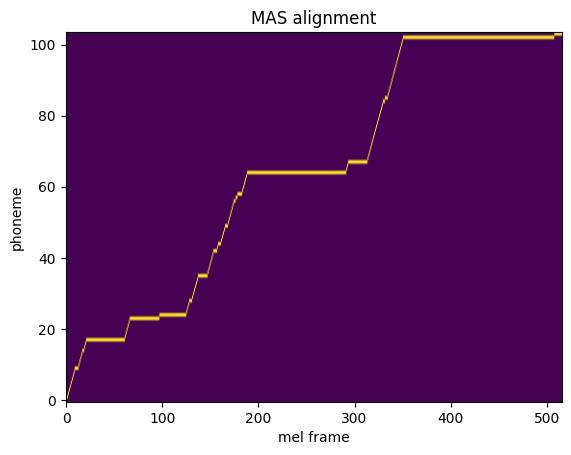

In [16]:
import importlib, tts.align
importlib.reload(tts.align)
from tts.align import log_likelihood, maximum_path
import matplotlib.pyplot as plt

h, mu, pad_mask = enc(ids)
score = log_likelihood(mu, mels)
path = maximum_path(score, ids_lens, mel_lens)    # (B, T_mel, T_text)

durations = path.sum(axis=1)    # 1. frames per phoneme: add up the path over the frame axis (dim=1)
mu_y = path @ mu # 2. prior for every frame: matrix-multiply path (B, T_mel, T_text) with mu (B, T_text, 80)

print('durations:', durations.shape, ' mu_y:', mu_y.shape)
print('durations sum:', durations.sum(1).tolist(), ' mel lengths:', mel_lens.tolist())
print('every phoneme ≥ 1 frame?', bool((durations[0, :ids_lens[0]] >= 1).all()))

plt.imshow(path[0, :mel_lens[0], :ids_lens[0]].T, aspect='auto', origin='lower')
plt.xlabel('mel frame'); plt.ylabel('phoneme'); plt.title('MAS alignment'); plt.show()

## Decoder

In [18]:
%%writefile tts/decoder.py
# Flow-matching decoder inspired by Matcha-TTS (Mehta et al., 2024), using OT-CFM (Lipman et al., 2023).
# Simplified: a 1-D residual conv network instead of Matcha's U-Net with Transformer blocks.
import math, torch, torch.nn as nn, torch.nn.functional as F

class TimeEmbedding(nn.Module):
    """Turns the time t (a single number per clip) into a vector the network can use."""
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
        self.mlp = nn.Sequential(nn.Linear(dim, dim * 4), nn.SiLU(), nn.Linear(dim * 4, dim))

    def forward(self, t):                                   # t: (B,)
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
        args = 1000 * t[:, None] * freqs[None]
        return self.mlp(torch.cat([args.sin(), args.cos()], dim=1))   # (B, dim)

class ResBlock(nn.Module):
    def __init__(self, ch, dilation):
        super().__init__()
        self.norm1, self.norm2 = nn.GroupNorm(8, ch), nn.GroupNorm(8, ch)
        self.conv1 = nn.Conv1d(ch, ch, 3, padding=dilation, dilation=dilation)
        self.conv2 = nn.Conv1d(ch, ch, 3, padding=1)
        self.time = nn.Linear(ch, ch)

    def forward(self, x, mask, temb):
        y = self.conv1(F.silu(self.norm1(x))) * mask
        y = y + self.time(temb)[:, :, None]                 # tell the block what time it is
        y = self.conv2(F.silu(self.norm2(y))) * mask
        return (x + y) * mask                               # residual connection

class FlowDecoder(nn.Module):
    def __init__(self, n_mels=80, ch=256, n_blocks=8, sigma_min=1e-4):
        super().__init__()
        self.sigma_min = sigma_min
        self.time = TimeEmbedding(ch)
        self.inp = nn.Conv1d(2 * n_mels, ch, 1)             # input: x_t and mu_y stacked
        self.blocks = nn.ModuleList([ResBlock(ch, 2 ** (i % 4)) for i in range(n_blocks)])
        self.out = nn.Conv1d(ch, n_mels, 1)

    def forward(self, x, mask, mu_y, t):
        """x, mu_y: (B, 80, T); mask: (B, 1, T); t: (B,) -> predicted direction (B, 80, T)"""
        temb = self.time(t)
        h = self.inp(torch.cat([x, mu_y], dim=1)) * mask
        for blk in self.blocks:
            h = blk(h, mask, temb)
        return self.out(h) * mask

    def loss(self, x1, mask, mu_y):
        x0 = torch.randn_like(x1)                           # random noise, same shape as the mel
        t = torch.rand(x1.shape[0], device=x1.device)       # one random time per clip
        tt = t[:, None, None]                               # reshaped so it multiplies (B, 80, T)
        x_t = (1 - (1 -self.sigma_min) * tt) * x0 + tt * x1                                # 1. point partway along the line
        u = x1 - (1 - self.sigma_min) * x0                                         # 2. direction of the line
        v = self(x_t, mask, mu_y, t)                        # decoder's predicted direction
        return ((v - u) ** 2 * mask).sum() / (mask.sum() * x1.shape[1])

    @torch.no_grad()
    def sample(self, mu_y, mask, n_steps=10, temperature=1.0):
        """Inference: start from noise and take n_steps small steps toward a mel."""
        x = torch.randn_like(mu_y) * temperature
        dt = 1.0 / n_steps
        for i in range(n_steps):
            t = torch.full((mu_y.shape[0],), i * dt, device=mu_y.device)
            x = x + dt * self(x, mask, mu_y, t)
        return x * mask

Writing tts/decoder.py


## Test Decoder

In [18]:
import importlib, tts.decoder, torch
importlib.reload(tts.decoder)
from tts.decoder import FlowDecoder

dec = FlowDecoder()
T = mels.shape[2]
mask = (torch.arange(T)[None] < mel_lens[:, None]).unsqueeze(1).float()   # (B, 1, T): 1 = real frame

loss = dec.loss(mels, mask, mu_y.transpose(1, 2))
print('flow-matching loss:', loss.item())

out = dec.sample(mu_y.transpose(1, 2), mask, n_steps=4)
print('sampled mel:', out.shape)
print('params:', sum(p.numel() for p in dec.parameters()) / 1e6, 'M')

flow-matching loss: 2.561190128326416
sampled mel: torch.Size([4, 80, 848])
params: 4.271696 M


##TTS MODEL

In [19]:
%%writefile tts/tts_model.py
# Combined model and losses following Matcha-TTS (Mehta et al., 2024) and Glow-TTS (Kim et al., 2020)
import math, torch, torch.nn as nn
from tts.model import TextEncoder, DurationPredictor
from tts.decoder import FlowDecoder
from tts.align import log_likelihood, maximum_path

def length_mask(lens, max_len):
    return (torch.arange(max_len, device=lens.device)[None] < lens[:, None]).float()

class TTSModel(nn.Module):
    def __init__(self, n_vocab, n_mels=80, dec_blocks=8):
        super().__init__()
        self.encoder = TextEncoder(n_vocab, n_mels=n_mels)
        self.dur = DurationPredictor()
        self.decoder = FlowDecoder(n_mels=n_mels, n_blocks=dec_blocks)

    def forward(self, ids, ids_lens, mels, mel_lens):
        h, mu, pad_mask = self.encoder(ids)                    # mu: (B, T_text, 80)
        x_mask = (~pad_mask).float()                           # (B, T_text): 1 = real phoneme
        y_mask = length_mask(mel_lens, mels.shape[2])          # (B, T_mel):  1 = real frame

        # Alignment (MAS itself has no gradients)
        path = maximum_path(log_likelihood(mu, mels), ids_lens, mel_lens)   # (B, T_mel, T_text)
        durations = path.sum(dim=1)                            # (B, T_text)

        # 1. Duration loss
        logw = self.dur(h, pad_mask)
        logw_target = torch.log(durations + 1e-8) * x_mask          # blank 1: log of durations (add 1e-8 so padding never takes log(0))
        dur_loss = ((logw - logw_target) ** 2).sum() / ids_lens.sum()

        # 2. Prior loss (Gaussian negative log-likelihood of the real mel under mu_y)
        mu_y = (path @ mu).transpose(1, 2)                     # (B, 80, T_mel)
        prior_loss = (0.5 * ((mels - mu_y) ** 2 + math.log(2 * math.pi)) * y_mask[:, None]).sum() \
                     / (y_mask.sum() * mels.shape[1])

        # 3. Flow-matching loss
        fm_loss = self.decoder.loss(mels, y_mask[:, None], mu_y)

        total = dur_loss + prior_loss + fm_loss                       # blank 2: combine the three losses
        return total, {'dur': dur_loss.item(), 'prior': prior_loss.item(), 'fm': fm_loss.item()}

Writing tts/tts_model.py


## Test

In [50]:
import importlib, tts.tts_model, torch
importlib.reload(tts.tts_model)
from tts.tts_model import TTSModel

device = 'cuda'
model = TTSModel(n_vocab=len(vocab)).to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-4)

batch = [x.to(device) for x in (ids, ids_lens, mels, mel_lens)]
for step in range(5):
    total, parts = model(*batch)
    opt.zero_grad()      # clear old gradients
    total.backward()     # compute how each weight should change
    opt.step()           # apply the change
    print(step, round(total.item(), 3), {k: round(v, 3) for k, v in parts.items()})

0 5.341 {'dur': 1.331, 'prior': 1.448, 'fm': 2.562}
1 4.634 {'dur': 1.143, 'prior': 1.421, 'fm': 2.071}
2 4.547 {'dur': 1.256, 'prior': 1.399, 'fm': 1.892}
3 4.421 {'dur': 1.251, 'prior': 1.378, 'fm': 1.792}
4 4.494 {'dur': 1.221, 'prior': 1.359, 'fm': 1.914}


In [20]:
%%writefile tts/train.py
import os, json, time, random
import numpy as np, torch
from torch.utils.data import DataLoader
from tts.data import TTSDataset, collate
from tts.text import load_vocab
from tts.tts_model import TTSModel

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()                                   # turn off dropout
    totals, n = {'dur': 0.0, 'prior': 0.0, 'fm': 0.0}, 0
    for batch in loader:
        _, parts = model(*[x.to(device) for x in batch])
        for k in totals:
            totals[k] += parts[k]
        n += 1
    model.train()                                  # back to training mode
    return {k: v / n for k, v in totals.items()}

def train(cfg):
    set_seed(cfg['seed'])
    device = 'cuda'
    torch.backends.cuda.matmul.allow_tf32 = True   # faster matrix maths on A100
    FL, ckpt_dir = cfg['filelist_dir'], cfg['checkpoint_dir']
    os.makedirs(ckpt_dir, exist_ok=True)

    vocab = load_vocab(f'{FL}/vocab.json')
    stats = f'{FL}/mel_stats.json'
    train_ds = TTSDataset(f'{FL}/train_processed.json', cfg['mel_dir'], stats)
    val_ds = TTSDataset(f'{FL}/val_processed.json', cfg['mel_dir'], stats)
    train_dl = DataLoader(train_ds, batch_size=cfg['batch_size'], shuffle=True,
                          collate_fn=collate, num_workers=2, drop_last=True)
    val_dl = DataLoader(val_ds, batch_size=cfg['batch_size'], shuffle=False,
                        collate_fn=collate, num_workers=2)

    model = TTSModel(n_vocab=len(vocab), dec_blocks=cfg['dec_blocks']).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg['lr'])

    # Resume from the last checkpoint if one exists
    start_epoch, best_val, log = 1, float('inf'), []
    last_path = f'{ckpt_dir}/last.ckpt'
    if os.path.exists(last_path):
        ck = torch.load(last_path, map_location=device)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt'])
        start_epoch, best_val, log = ck['epoch'] + 1, ck['best_val'], ck['log']
        print(f"Resumed from epoch {ck['epoch']}")

    for epoch in range(start_epoch, cfg['epochs'] + 1):
        t0, running = time.time(), []
        for batch in train_dl:
            total, parts = model(*[x.to(device) for x in batch])
            opt.zero_grad()                                # 1. clear old gradients
            total.backward()                                 # 2. compute gradients
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()                               # 3. update the weights
            running.append(total.item())

        val = evaluate(model, val_dl, device)
        val_total = sum(val.values())
        is_best = val_total < best_val
        best_val = min(best_val, val_total)

        entry = {'epoch': epoch, 'train': float(np.mean(running)), 'val': val_total,
                 **{f'val_{k}': v for k, v in val.items()}, 'sec': round(time.time() - t0, 1)}
        log.append(entry)
        print(entry)

        ck = {'model': model.state_dict(), 'opt': opt.state_dict(), 'epoch': epoch,
              'best_val': best_val, 'log': log, 'n_vocab': len(vocab), 'cfg': cfg}
        torch.save(ck, last_path)
        if is_best:
            torch.save(ck, f'{ckpt_dir}/best.ckpt')

    json.dump(log, open(f'{ckpt_dir}/log.json', 'w'), indent=1)
    return log

Writing tts/train.py


In [30]:
import importlib, tts.train
importlib.reload(tts.train)
from tts.train import train

base = {
    'seed': 42,               # your split seed
    'batch_size': 32,
    'lr': 1e-4,
    'epochs': 300,            # ~2.2 h per experiment at 26.6 s/epoch
    'filelist_dir': '/content/drive/MyDrive/ljspeech_filelists',
    'mel_dir': '/content/mels',
}
expA = {**base, 'dec_blocks': 8, 'checkpoint_dir': '/content/drive/MyDrive/tts_ckpt/expA'}
expB = {**base, 'dec_blocks': 4, 'checkpoint_dir': '/content/drive/MyDrive/tts_ckpt/expB'}

# Show the controlled change explicitly (useful evidence for the marker)
print({k: (expA[k], expB[k]) for k in expA if expA[k] != expB[k]})

{'dec_blocks': (8, 4), 'checkpoint_dir': ('/content/drive/MyDrive/tts_ckpt/expA', '/content/drive/MyDrive/tts_ckpt/expB')}


## Synth

In [21]:
%%writefile tts/synth.py
# HiFi-GAN vocoder (Kong et al., 2020): https://github.com/jik876/hifi-gan
# Official LJSpeech V1 generator weights and code, via the Matcha-TTS repo:
# https://github.com/shivammehta25/Matcha-TTS
import sys, torch
from tts.hifigan.config import v1
from tts.hifigan.env import AttrDict
from tts.hifigan.models import Generator
from tts.text import text_to_ids
from tts.tts_model import TTSModel

def load_vocoder(path, device='cuda'):
    voc = Generator(AttrDict(v1)).to(device)
    voc.load_state_dict(torch.load(path, map_location=device)['generator'])
    voc.eval(); voc.remove_weight_norm()
    return voc

def load_model(ckpt_path, vocoder_path, device='cuda'):
    ck = torch.load(ckpt_path, map_location=device)          # ck is created here
    model = TTSModel(n_vocab=ck['n_vocab'],
                     dec_blocks=ck['cfg'].get('dec_blocks', 8)).to(device)
    model.load_state_dict(ck['model']); model.eval()
    return model, load_vocoder(vocoder_path, device)

def durations_to_path(d, T_mel):
    """d: (T_text,) whole-number durations -> path (T_mel, T_text), like MAS's output"""
    end = torch.cumsum(d, 0)
    start = end - d
    frames = torch.arange(T_mel, device=d.device)[:, None]
    return ((frames >= start[None]) & (frames < end[None])).float()

@torch.no_grad()
def synthesize(text, model, vocoder, vocab, mel_mean, mel_std,
               n_steps=10, length_scale=1.0, temperature=0.667):
    device = next(model.parameters()).device
    ids = torch.tensor([text_to_ids(text, vocab)], device=device)   # (1, T_text)
    h, mu, pad_mask = model.encoder(ids)
    logw = model.dur(h, pad_mask)[0]                                # (T_text,) predicted log-durations
    d = torch.ceil(torch.exp(logw) * length_scale).long().clamp(min=1)                             # blank: log-durations -> whole frame counts
    T_mel = int(d.sum())
    mu_y = (durations_to_path(d, T_mel) @ mu[0]).T[None]           # (1, 80, T_mel)
    mask = torch.ones(1, 1, T_mel, device=device)
    mel = model.decoder.sample(mu_y, mask, n_steps=n_steps, temperature=temperature)
    mel = mel * mel_std + mel_mean                                  # undo normalization
    wav = vocoder(mel).squeeze().clamp(-1, 1).cpu().numpy()
    return wav, 22050

Writing tts/synth.py


In [23]:
!git clone -q https://github.com/shivammehta25/Matcha-TTS.git /content/Matcha-TTS 2>/dev/null || echo "already cloned"
!wget -q -O /content/drive/MyDrive/tts_ckpt/hifigan_lj_v1 \
    https://github.com/shivammehta25/Matcha-TTS-checkpoints/releases/download/v1.0/generator_v1
!ls -lh /content/drive/MyDrive/tts_ckpt/hifigan_lj_v1

-rw------- 1 root root 54M Jan 12  2024 /content/drive/MyDrive/tts_ckpt/hifigan_lj_v1


In [24]:
!cp -r /content/Matcha-TTS/matcha/hifigan /content/tts/hifigan
!ls /content/tts/hifigan

config.py    env.py	  LICENSE	 models.py  xutils.py
denoiser.py  __init__.py  meldataset.py  README.md


In [31]:
!ls /content/Matcha-TTS/matcha/hifigan

config.py    env.py	  LICENSE	 models.py  xutils.py
denoiser.py  __init__.py  meldataset.py  README.md


In [54]:
import importlib, json, os, torch, soundfile as sf
import tts.synth
importlib.reload(tts.synth)
from tts.synth import load_model, synthesize
from tts.text import load_vocab
from IPython.display import Audio, display

FL   = '/content/drive/MyDrive/ljspeech_filelists'
VOC  = '/content/drive/MyDrive/tts_ckpt/hifigan_lj_v1'
CKPT = '/content/drive/MyDrive/tts_ckpt/smoke/last.ckpt'

model, voc = load_model(CKPT, VOC)
vocab = load_vocab(f'{FL}/vocab.json')
stats = json.load(open(f'{FL}/mel_stats.json'))

wav, sr = synthesize("Hello world.", model, voc, vocab, stats['mel_mean'], stats['mel_std'])

os.makedirs('wav_examples', exist_ok=True)
sf.write('wav_examples/smoke_test.wav', wav, sr)
print(f'Saved wav_examples/smoke_test.wav ({len(wav) / sr:.2f} s)')
display(Audio(wav, rate=sr))

Removing weight norm...
Saved wav_examples/smoke_test.wav (0.50 s)


In [36]:
display(Audio('/content/LJSpeech-1.1/wavs/LJ001-0001.wav'))

In [ ]:

# (Optional) Put your pipeline wiring here:
# - load model + vocoder
# - synthesize from a single input text
# - write .wav to wav_examples/

# 1.3 Experimental methodology (Rubric 1.3)

## 1.3.1 Controlled experiments (minimum: 2)
Define at least two experiments that share the **same split** and differ by a clearly stated change.

### Experiment A (baseline)
- **Name:** `expA`  
- **Purpose:** `<baseline objective>`  
- **Key settings:** `<model, vocoder, steps/epochs, batch size, lr, etc.>`

### Experiment B (controlled change)
- **Name:** `expB`  
- **Controlled change vs expA:** `<one major variable is best>`  
- **Key settings:** `<only what differs + key training settings>`

## 1.3.2 What you saved for reproducibility
- Config files: `<paths>`
- Random seeds: `<where set>`
- Checkpoints: `<paths>`
- Logs: `<paths>`

# Experiment A Run


In [55]:
import importlib, tts.train
importlib.reload(tts.train)
from tts.train import train
logA = train(expA)

{'epoch': 1, 'train': 3.2857938060702168, 'val': 2.7608768445689504, 'val_dur': 0.9456938839540249, 'val_prior': 1.0978632932756005, 'val_fm': 0.717319667339325, 'sec': 24.9}
{'epoch': 2, 'train': 2.6124567438703066, 'val': 2.4748159341695835, 'val_dur': 0.8056760953693856, 'val_prior': 1.0867535689981973, 'val_fm': 0.5823862698020005, 'sec': 25.2}
{'epoch': 3, 'train': 2.425461053119158, 'val': 2.3415851876503084, 'val_dur': 0.7291973640279072, 'val_prior': 1.0824279319949266, 'val_fm': 0.5299598916274745, 'sec': 25.4}
{'epoch': 4, 'train': 2.335472027460734, 'val': 2.2795722121145667, 'val_dur': 0.6841285781162542, 'val_prior': 1.0798697936825636, 'val_fm': 0.515573840315749, 'sec': 25.2}
{'epoch': 5, 'train': 2.280924735812966, 'val': 2.23534316478706, 'val_dur': 0.6617377880142956, 'val_prior': 1.0784169202897607, 'val_fm': 0.4951884564830036, 'sec': 25.0}
{'epoch': 6, 'train': 2.241381482611373, 'val': 2.2183929790810843, 'val_dur': 0.6542184411025629, 'val_prior': 1.0782805594002

In [25]:
import json, torch, importlib, matplotlib.pyplot as plt
import tts.model, tts.decoder, tts.tts_model, tts.synth
for m in (tts.model, tts.decoder, tts.tts_model, tts.synth):
    importlib.reload(m)
from tts.synth import load_model, synthesize
from tts.text import load_vocab
from IPython.display import Audio, display

FL  = '/content/drive/MyDrive/ljspeech_filelists'
VOC = '/content/drive/MyDrive/tts_ckpt/hifigan_lj_v1'
CK  = '/content/drive/MyDrive/tts_ckpt/expA'

# 1. Which epoch is "best", and did training finish?
best = torch.load(f'{CK}/best.ckpt', map_location='cpu')
last = torch.load(f'{CK}/last.ckpt', map_location='cpu')
print(f"best.ckpt: epoch {best['epoch']}, val = {best['best_val']:.4f}")
print(f"last.ckpt: epoch {last['epoch']} of {last['cfg']['epochs']}")

# 2. Loss curves (the full log lives in last.ckpt)
log = last['log']
ep = [e['epoch'] for e in log]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, [e['train'] for e in log], label='train')
ax[0].plot(ep, [e['val'] for e in log], label='val')
ax[0].set_title('expA total loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
for k in ['val_dur', 'val_prior', 'val_fm']:
    ax[1].plot(ep, [e[k] for e in log], label=k)
ax[1].set_title('expA validation loss parts'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.show()

# 3. Listen
model, voc = load_model(f'{CK}/best.ckpt', VOC)
vocab = load_vocab(f'{FL}/vocab.json')
stats = json.load(open(f'{FL}/mel_stats.json'))
for text in ["Hello world.",
             "The quick brown fox jumps over the lazy dog, and then it runs away."]:
    wav, sr = synthesize(text, model, voc, vocab, stats['mel_mean'], stats['mel_std'])
    print(f'{text}  ({len(wav) / sr:.2f} s)')
    display(Audio(wav, rate=sr))

best.ckpt: epoch 253, val = 1.7893
last.ckpt: epoch 300 of 300


/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Removing weight norm...


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Hello world.  (0.84 s)


The quick brown fox jumps over the lazy dog, and then it runs away.  (4.95 s)


In [ ]:
%%writefile tts/metrics.py
import time, torch

def measure_rtf(text, model, voc, vocab, mean, std, synthesize, n_runs=5, **kw):
    synthesize(text, model, voc, vocab, mean, std, **kw)        # warm-up, not timed
    times = []
    for _ in range(n_runs):
        torch.cuda.synchronize(); t0 = time.perf_counter()
        wav, sr = synthesize(text, model, voc, vocab, mean, std, **kw)
        torch.cuda.synchronize(); times.append(time.perf_counter() - t0)
    synth_time = sum(times) / n_runs
    audio_dur = len(wav) / sr
    rtf = synth_time / audio_dur                                          # blank: RTF definition
    return wav, sr, synth_time, audio_dur, rtf

In [ ]:
import importlib
import tts.model, tts.decoder, tts.tts_model, tts.train
for m in (tts.model, tts.decoder, tts.tts_model, tts.train):
    importlib.reload(m)

from tts.train import train
logB = train(expB)

{'epoch': 1, 'train': 3.322826358521021, 'val': 2.784929096698761, 'val_dur': 0.9702781002695967, 'val_prior': 1.098346117066174, 'val_fm': 0.7163048793629903, 'sec': 77.3}
{'epoch': 2, 'train': 2.592872992932614, 'val': 2.4341697482074176, 'val_dur': 0.7900206693788854, 'val_prior': 1.0863164692390255, 'val_fm': 0.557832609589507, 'sec': 75.7}
{'epoch': 3, 'train': 2.405636928861659, 'val': 2.3369345207039904, 'val_dur': 0.7230490068110024, 'val_prior': 1.0818367614978697, 'val_fm': 0.5320487523951182, 'sec': 75.6}
{'epoch': 4, 'train': 2.3179912917110896, 'val': 2.254998786420357, 'val_dur': 0.6789968856951085, 'val_prior': 1.07963154083345, 'val_fm': 0.49637035989179845, 'sec': 74.9}
{'epoch': 5, 'train': 2.273056432012389, 'val': 2.216527085478713, 'val_dur': 0.659551467837357, 'val_prior': 1.0785539673595894, 'val_fm': 0.4784216502817666, 'sec': 75.4}
{'epoch': 6, 'train': 2.2422408277470764, 'val': 2.2074250593418028, 'val_dur': 0.6509402452445612, 'val_prior': 1.0780814042905482

In [ ]:

# (Optional) Run/record your experiment commands here (or print them):
# !python scripts/train.py --config configs/expA.yaml
# !python scripts/train.py --config configs/expB.yaml

# (Required) Produce qualitative samples (≥10 prompts) and save wavs
# Example pattern:
# prompts = [...]
# for i, t in enumerate(prompts):
#     out = f"wav_examples/sample_{i:02d}.wav"
#     synthesize_to_wav(text=t, checkpoint="...", out_path=out)

# (Required) Compute objective metric(s) and report metric results clearly in the notebook.# 1.4 Evaluation, coding practice & attribution (Rubric 1.4)

## 1.4.1 Objective metric (minimum: 1) — report for each experiment
Implement and report at least one objective metric for **each** experiment, e.g.:
- **Latency:** average synthesis time per sentence (state number of runs)  
- **Real-Time Factor (RTF):** synthesis_time / audio_duration  
- **Other justified metric:** `<describe and justify>`

Report results in a small table (in this notebook)

## 1.4.2 Qualitative evaluation (required)
Provide **≥10 text prompts** and corresponding **generated `.wav` outputs** (per your task requirements).  
Include:
- The list of prompts you used
- Where the `.wav` files are saved (`wav_examples/…`)
- (Optional) a short comment on perceptual quality differences between experiments

> Spectrograms are optional unless explicitly required by your task sheet. If you include them, add 2–3 representative samples per experiment in `results/spectrograms/`.

## 1.4.3 Coding practice & clarity
Briefly state:
- How you organised code (modules/scripts/configs)
- Any key engineering choices that improve reproducibility (fixed seeds, clear CLI args, etc.)

## 1.4.4 Attribution / external resources
List any:
- External libraries/models/toolkits used
- Pretrained checkpoints used
- Tutorials or code snippets adapted (with links in your report; in this notebook, name them clearly)

## 1.4.5 AI use statement (if any)
State whether you used generative AI tools, and for what (e.g., debugging, refactoring, documentation).  
If used, specify what you verified yourself and what parts were AI-assisted.

In [ ]:
import os, json, torch, importlib, soundfile as sf, pandas as pd
import tts.metrics, tts.synth
importlib.reload(tts.metrics); importlib.reload(tts.synth)
from tts.synth import load_model, synthesize
from tts.text import load_vocab
from tts.metrics import measure_rtf
from IPython.display import Audio, display

FL  = '/content/drive/MyDrive/ljspeech_filelists'
VOC = '/content/drive/MyDrive/tts_ckpt/hifigan_lj_v1'
CK  = '/content/drive/MyDrive/tts_ckpt'
exps = ['expA', 'expB']

vocab = load_vocab(f'{FL}/vocab.json')
stats = json.load(open(f'{FL}/mel_stats.json'))
os.makedirs('wav_examples', exist_ok=True)
os.makedirs('results', exist_ok=True)

prompts = [
    # Short and simple
    "Good morning.",
    "Thank you very much.",
    # Questions (intonation)
    "Have you seen the weather forecast for tomorrow?",
    "Where did you leave the keys?",
    # Long sentences with commas (alignment robustness)
    "The old library, which had been closed for nearly a decade, finally reopened its doors to the public last spring.",
    "After the meeting ended, the committee gathered their papers, thanked the speaker, and quietly left the hall.",
    # Numbers written as words
    "The train departs at seven forty five and arrives two hours later.",
    "She paid twenty three dollars for the book.",
    # Tricky or rare words
    "The archaeologist examined the ancient manuscript with great enthusiasm.",
    "Particularly unusual phenomena were observed throughout the experiment.",
    # Modern topics outside LJSpeech's nineteenth and early twentieth century style
    "Please remember to charge your phone before the video call.",
    "Artificial intelligence can now generate natural sounding speech from text.",
]

rows = []
for exp in exps:
    best_path = f'{CK}/{exp}/best.ckpt'
    if not os.path.exists(best_path):
        print(f'{exp}: no checkpoint yet, skipping'); continue

    best = torch.load(best_path, map_location='cpu')
    last = torch.load(f'{CK}/{exp}/last.ckpt', map_location='cpu')
    print(f"{exp} best.ckpt: epoch {best['epoch']}, val = {best['best_val']:.4f}")
    print(f"{exp} last.ckpt: epoch {last['epoch']} of {last['cfg']['epochs']}")

    model, voc = load_model(best_path, VOC)

    for i, text in enumerate(prompts, start=1):
        out = f'wav_examples/{exp}_{i:02d}.wav'
        wav, sr, t, dur, rtf = measure_rtf(text, model, voc, vocab,
                                           stats['mel_mean'], stats['mel_std'], synthesize)
        sf.write(out, wav, sr)
        rows.append({'exp': exp, 'prompt': i, 'synth_s': t, 'audio_s': dur, 'rtf': rtf})
        print(f'  {out}  RTF={rtf:.4f}  {text}')

df = pd.DataFrame(rows)
df.to_csv('results/metrics.csv', index=False)

summary = df.groupby('exp')[['synth_s', 'audio_s', 'rtf']].agg(['mean', 'std']).round(4)
display(summary)

for exp in exps:
    path = f'wav_examples/{exp}_01.wav'
    if os.path.exists(path):
        print(path); display(Audio(path))

# (Required) Produce qualitative samples (≥10 prompts) and save wavs
# Example pattern:
# prompts = [...]
# for i, t in enumerate(prompts):
#     out = f"wav_examples/sample_{i:02d}.wav"
#     synthesize_to_wav(text=t, checkpoint="...", out_path=out)
# (Required) Compute objective metric(s) and report metric results clearly in the notebook.

# Final verification (before submission)

## Restart & run
Restart the kernel and run all cells you want the marker to execute, ensuring:
- No hidden dependencies on your local machine paths
- Commands/paths work from the submission root

## Confirm required artefacts exist
- `wav_examples/` contains generated `.wav` outputs (**≥10 prompts**)  
- bjective metric results for each experiment are clearly reported in the notebook
- dependency file exists (`requirements.txt` / `environment.yml` / etc.)  
- inference entrypoint works (single command that takes text and outputs wav)

## Marker instructions (one paragraph)
Write a short paragraph here telling the marker **exactly** how to:
1) install deps, 2) run training (or load checkpoints), 3) run inference demo, 4) locate results.